# Crop Recommendation System

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# load dataset
df = pd.read_csv(r"Crop_recommendation.csv")
df

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice
...,...,...,...,...,...,...,...,...
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee


In [3]:
#Printing Dimension of datasets
print("Dimension of dataset:", df.shape)
print("Number of rows in the dataset:", df.shape[0])
print("Number of columns in the dataset:", df.shape[1])

Dimension of dataset: (2200, 8)
Number of rows in the dataset: 2200
Number of columns in the dataset: 8


In [4]:
# printing attributes (columns) name
print("Column Names:",df.columns.values)

Column Names: <ArrowStringArray>
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
Length: 8, dtype: str


## Exploratory data analysis

In [5]:
# Showing datatypes of the columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB


In [6]:
# getting discriptive statistcs (Summary of the data)
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [7]:
#data points for each class
df.label.value_counts()

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

Text(0.5, 1.0, 'Crop distribution')

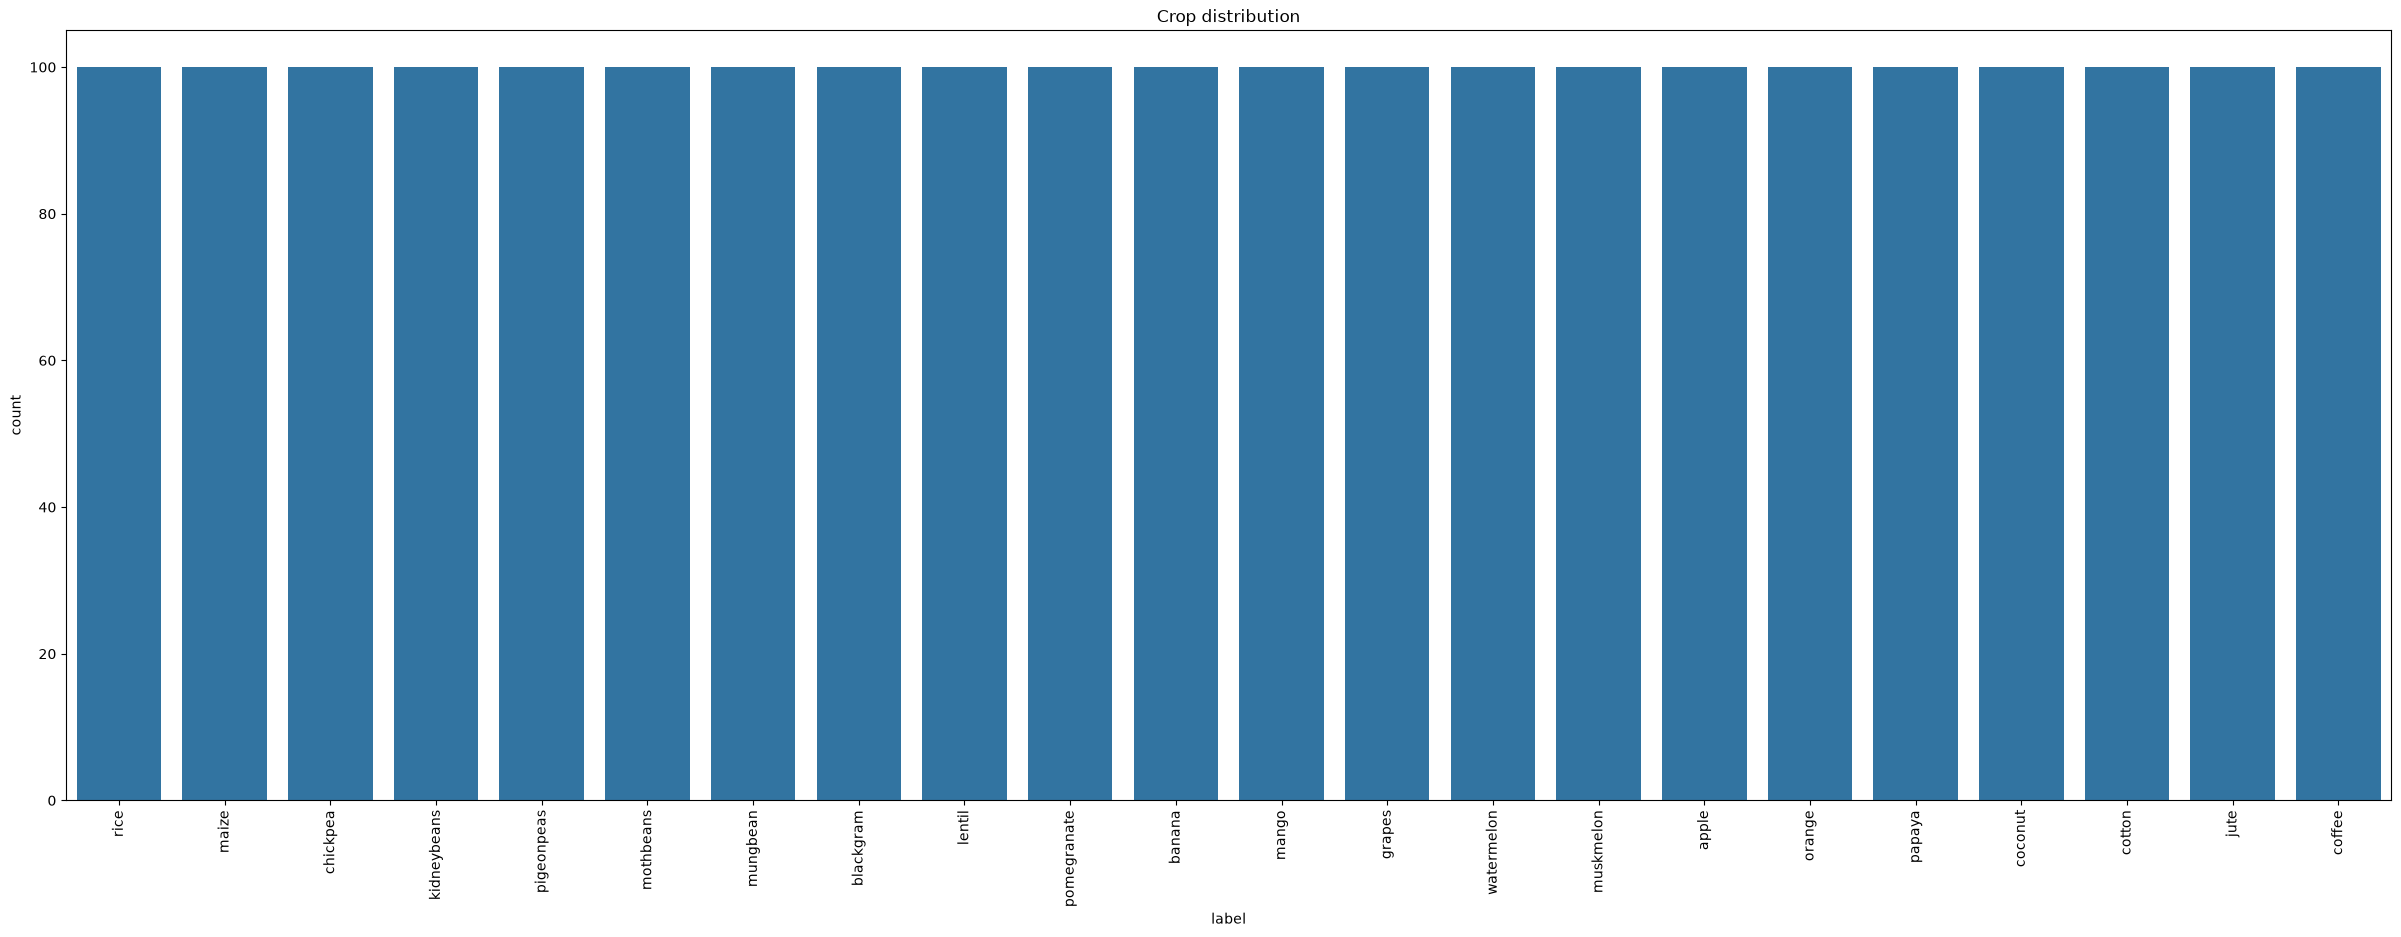

In [8]:
#Count plot for the number of crops
plt.figure(figsize=(30,10))
sns.countplot(x='label',data = df)
plt.xticks(rotation=90)
plt.title("Crop distribution")

This shows that the number of crops of each category are balanced i.e. equal in number and all 22 classes are represented.

#### check missing values

In [9]:
df.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [10]:
(df.isnull().sum()/len(df))*100

N              0.0
P              0.0
K              0.0
temperature    0.0
humidity       0.0
ph             0.0
rainfall       0.0
label          0.0
dtype: float64

No missing values found in the dataframe

### Outlier detection and skewness

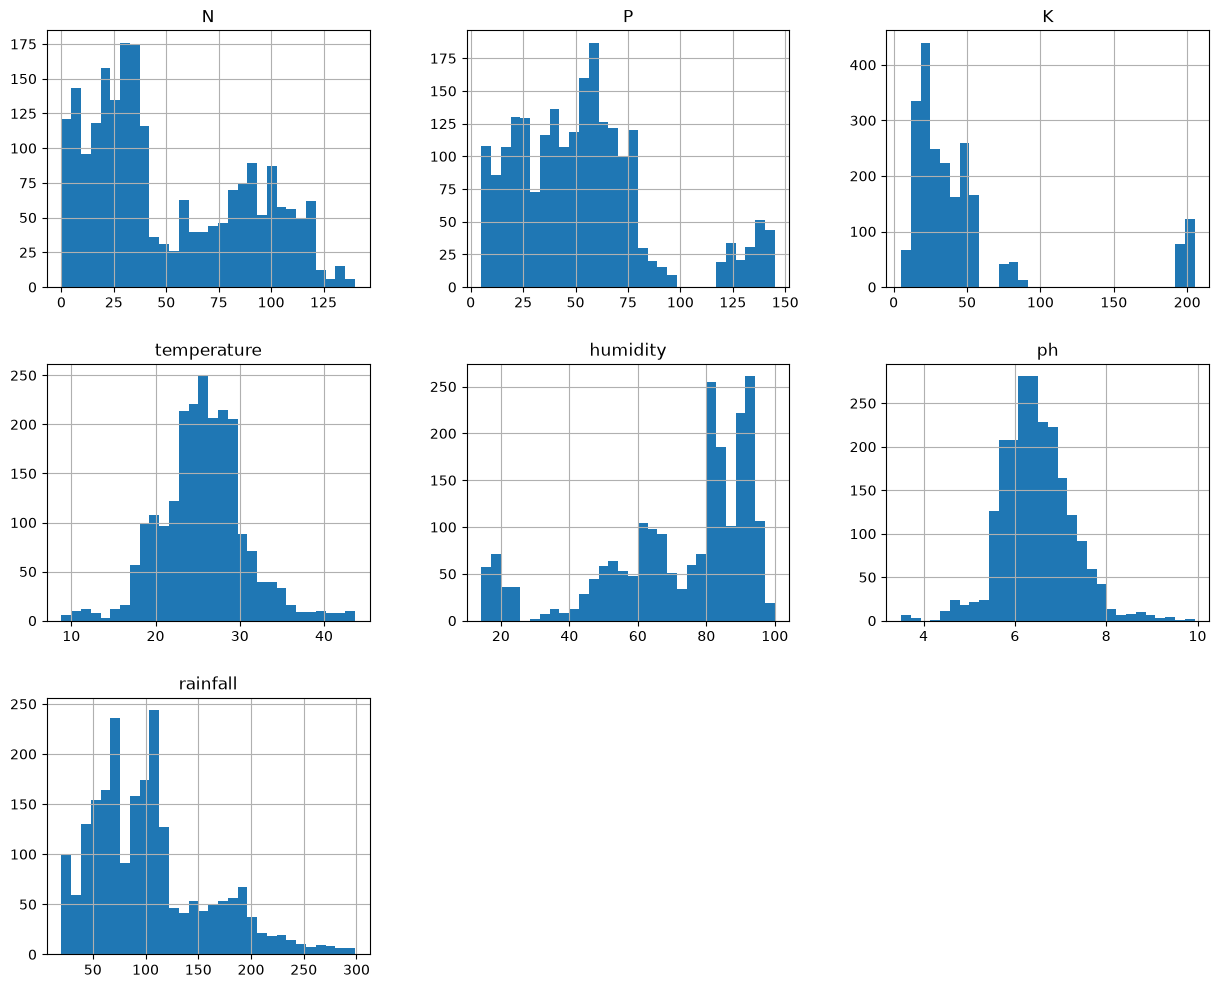

In [11]:
num_cols = df.select_dtypes(include=['int64','float64']).columns

df[num_cols].hist(
    figsize=(15,12),
    bins=30)
plt.show()

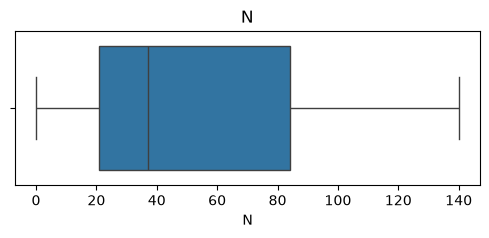

Q1:21.0, Q3:84.25, IQR:63.25
lower: -73.875, Upper: 179.125
Outliers:  0


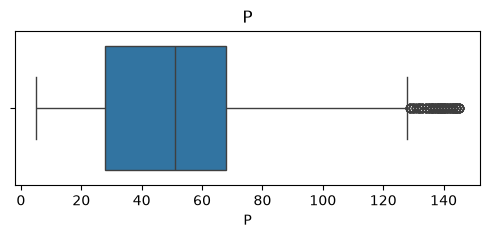

Q1:28.0, Q3:68.0, IQR:40.0
lower: -32.0, Upper: 128.0
Outliers:  138


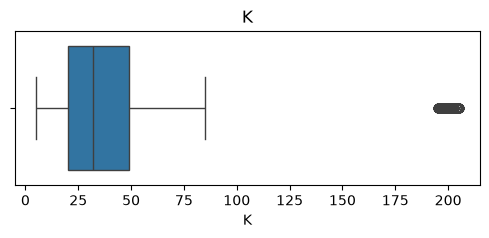

Q1:20.0, Q3:49.0, IQR:29.0
lower: -23.5, Upper: 92.5
Outliers:  200


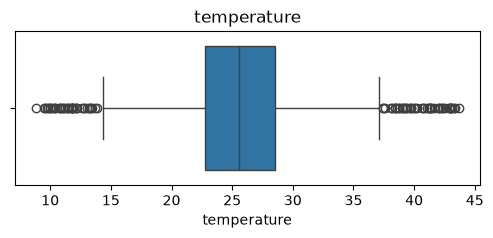

Q1:22.7693746325, Q3:28.5616539325, IQR:5.792279300000001
lower: 14.080955682499999, Upper: 37.2500728825
Outliers:  86


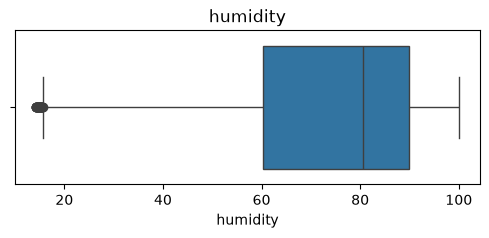

Q1:60.2619528025, Q3:89.948770755, IQR:29.6868179525
lower: 15.731725873750001, Upper: 134.47899768374998
Outliers:  30


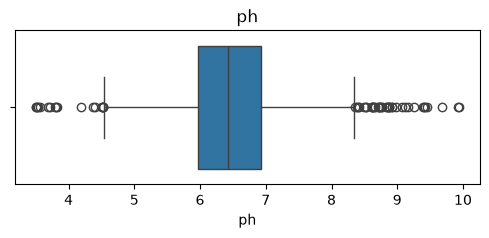

Q1:5.97169279925, Q3:6.923642621250002, IQR:0.9519498220000013
lower: 4.543768066249998, Upper: 8.351567354250005
Outliers:  57


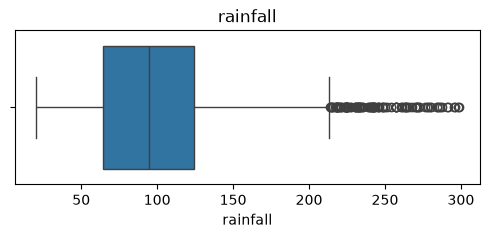

Q1:64.55168599999999, Q3:124.2675078, IQR:59.715821800000015
lower: -25.022046700000033, Upper: 213.84124050000003
Outliers:  100


In [12]:
# Skewness
df.skew(numeric_only=True)

# Outlier visualization
for col in df.columns[:-1]:
    plt.figure(figsize=(6,2))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    print("Q1:{}, Q3:{}, IQR:{}".format(Q1, Q3, IQR))
    print("lower: {}, Upper: {}".format(lower, upper))
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print("Outliers: ",len(outliers))

Boxplot analysis revealed the presence of outliers in Phosphorus (P), Potassium (K), pH, Temperature, and Rainfall. Potassium and Rainfall exhibited the highest number of extreme observations with strong positive skewness. Since these values represent natural variations in soil nutrients and climatic conditions rather than data-entry errors, the outliers were retained. Instead of removing observations, appropriate feature scaling techniques were considered for distance-based machine learning algorithms.

### Correlation Analysis

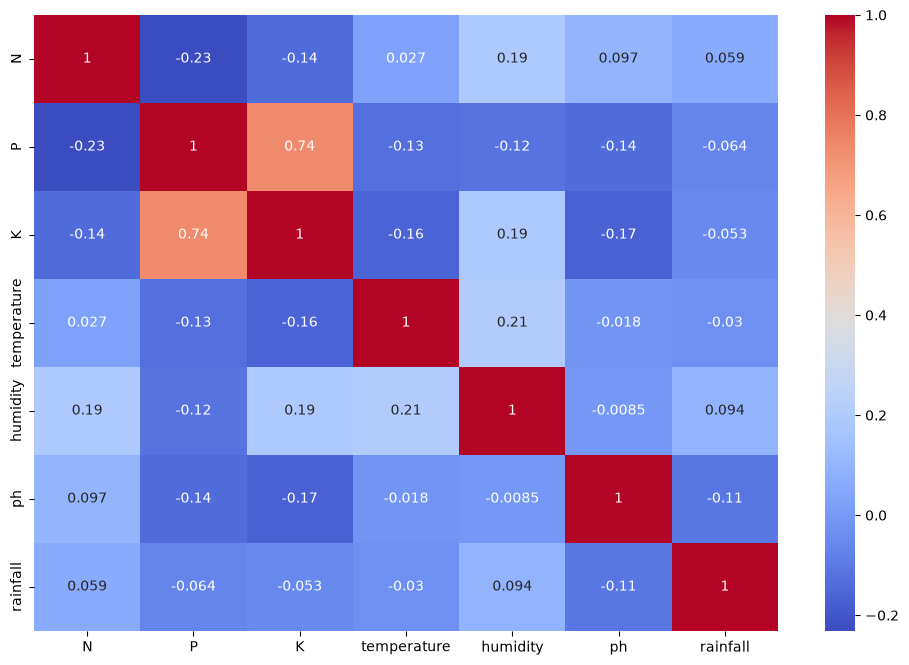

In [13]:
corr = df[num_cols].corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.show()

Strong Positive Correlation approx 0.74: There is a notable, strong positive correlation between P (Phosphorus) and K (Potassium). This suggests that soil samples high in phosphorus tend to be high in potassium as well.

Weak/Moderate Correlations: Most of the other feature pairs show values close to (0) (ranging roughly between (-0.23) and (0.21). 
For instance:
* Temperature and humidity show a slight positive correlation (0.21).
* Nitrogen has a weak negative correlation with Phosphorus (-0.23) and Potassium (-0.14).

<Figure size 3000x2000 with 0 Axes>

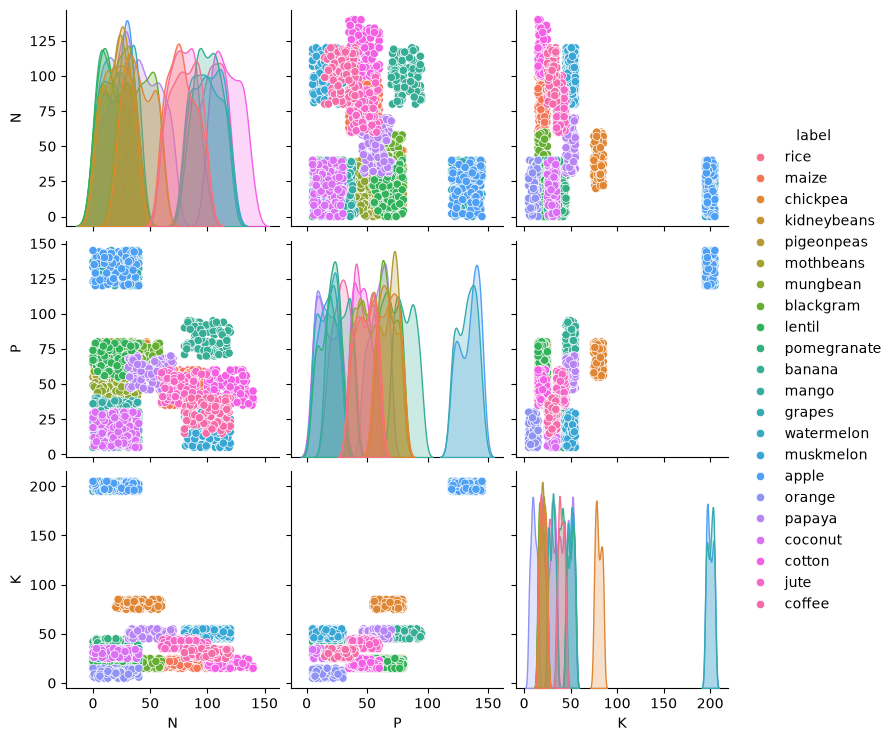

In [14]:
plt.figure(figsize=(30,20))
sns.pairplot(df[['N','P','K','label']], hue='label')
plt.show()

* N, P and K show clear clusters for several crops because they have distinct form, tight clusters or blocky groups rather than overlapping completely.
* Certain crops have very narrow, specific requirements for soil nutrients or climate parameters. For example, some crops exclusively grow in low-pH or high-rainfall zones. This proves that non-linear models (like Random Forest, XGBoost or Support Vector Machines with RBF kernels) will likely perform much better than a simple linear classifier, as the decision boundaries are segmented.

<Figure size 3000x2000 with 0 Axes>

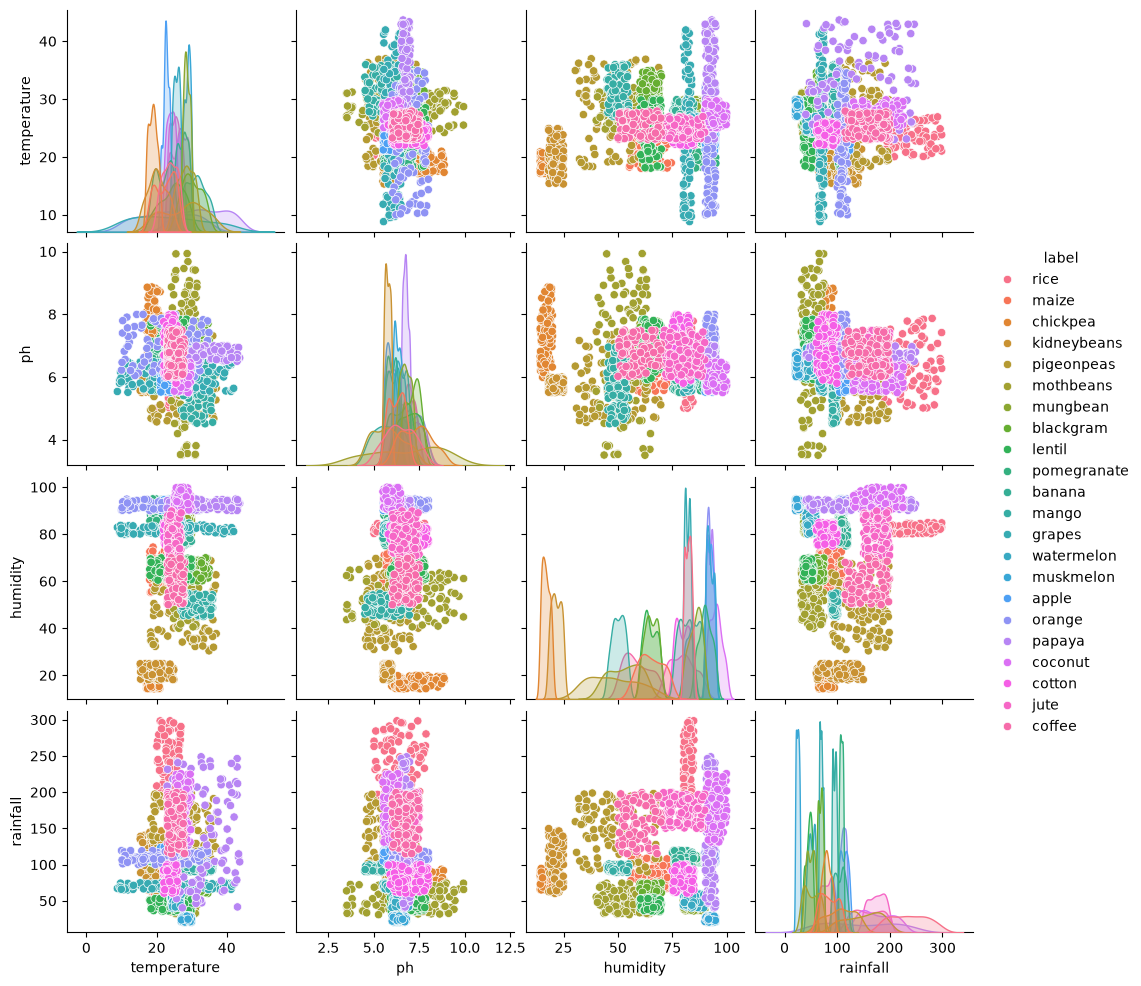

In [15]:
plt.figure(figsize=(30,20))
sns.pairplot(df[['temperature','ph','humidity','rainfall','label']], hue='label')
plt.show()

* This shows that some crops like mothbean are grown on low ph that is acidic soil.
* Orange and Papaya are grown on high humid environment and Chickpea on low humid enivronment.
* Features like rainfall and K (Potassium) show heavy skewness, meaning a few crops require exceptionally high values while most require lower values.
* Some crops can be easily classified which require high nutrients like phosphorus and Potassium but there are overlapping in different crops so it suggests that we use classifiers such as Random forest instead of linear models.

### Applying PCA

In [16]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import  RobustScaler

X = df.drop('label', axis=1)
y = df['label']

X_scaled = RobustScaler().fit_transform(X)

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

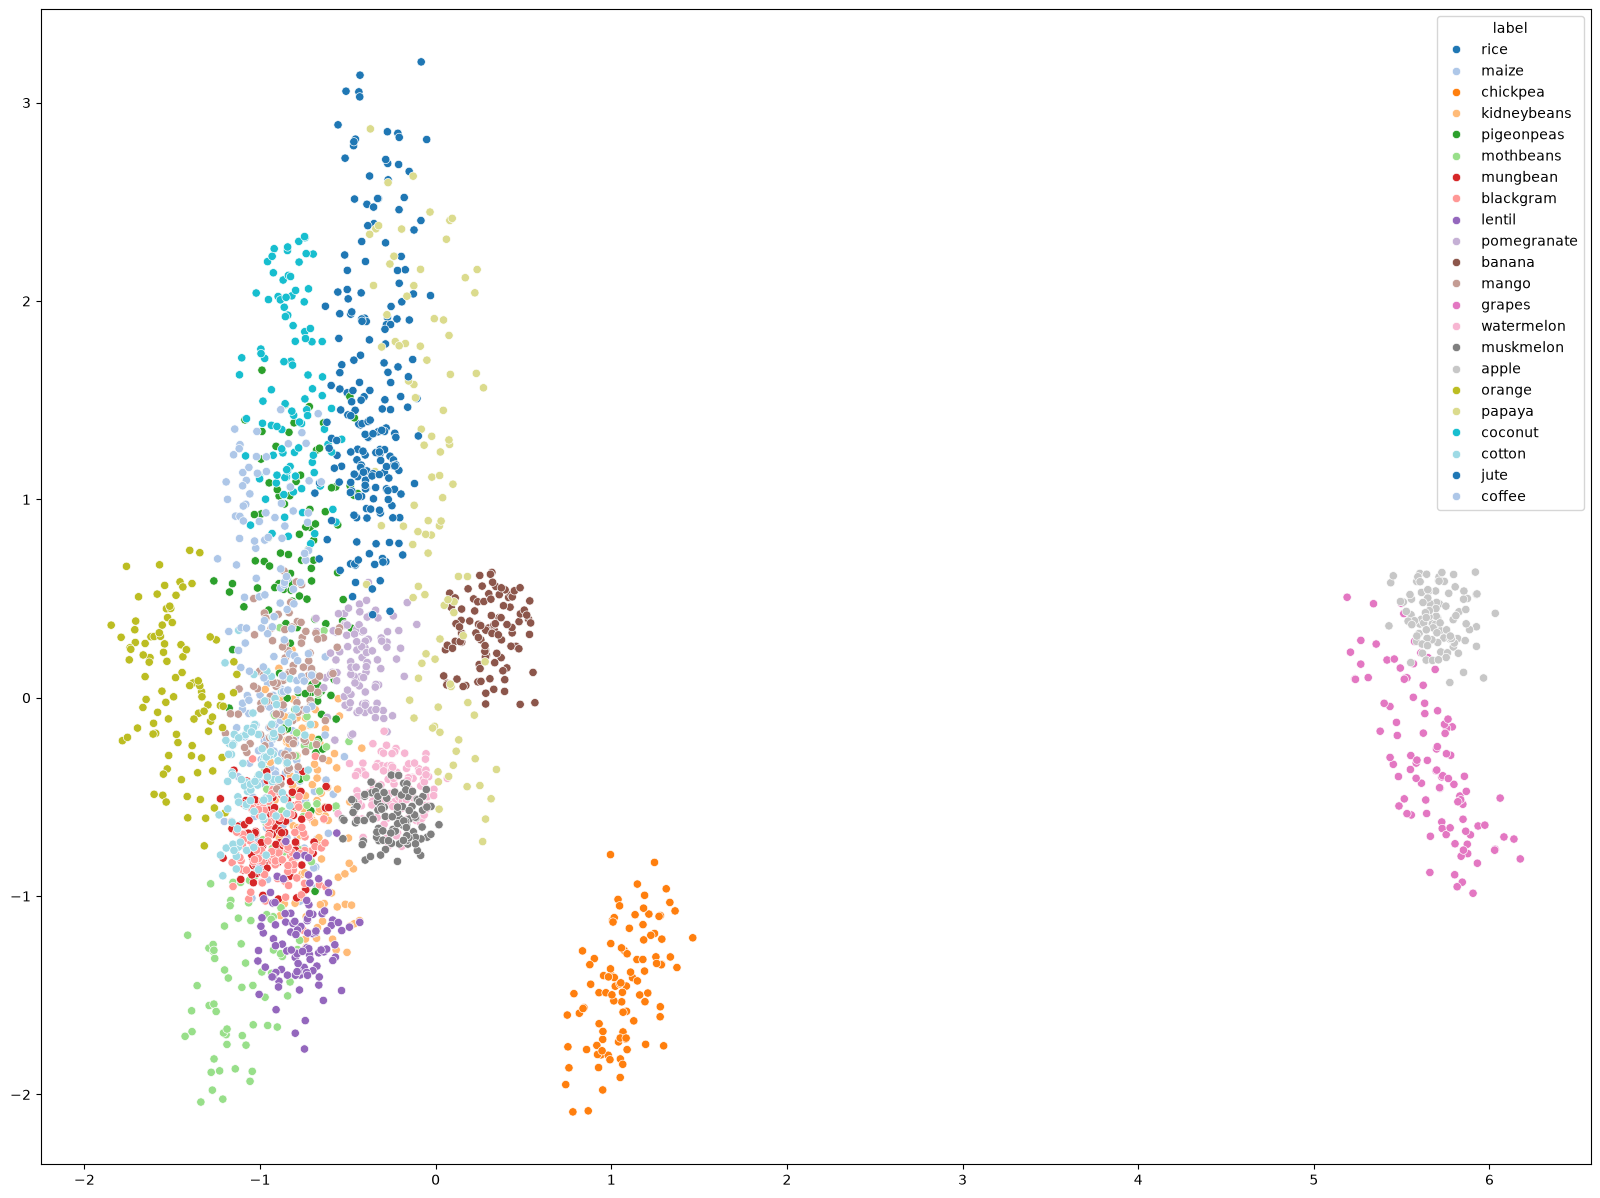

In [17]:
plt.figure(figsize=(20,15))

sns.scatterplot( x=X_pca[:,0], y=X_pca[:,1], hue=y, palette='tab20')
plt.show()

* The classes are naturally clustered. However, some classes are not densely packed with each other and are sparse.
* Here, many classes are overlapped and there is no clear distinction.

## Data Preprocessing

### Converting crop label into numeric

In [18]:
# Import label encoder 
from sklearn import preprocessing 
  
# label_encoder object knows how to understand word labels. 
label_encoder = preprocessing.LabelEncoder() 
  
# Encode labels in column 'species'. 
df['label']= label_encoder.fit_transform(df['label']) 

label_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("Label Mapping:", label_mapping)

Label Mapping: {'apple': np.int64(0), 'banana': np.int64(1), 'blackgram': np.int64(2), 'chickpea': np.int64(3), 'coconut': np.int64(4), 'coffee': np.int64(5), 'cotton': np.int64(6), 'grapes': np.int64(7), 'jute': np.int64(8), 'kidneybeans': np.int64(9), 'lentil': np.int64(10), 'maize': np.int64(11), 'mango': np.int64(12), 'mothbeans': np.int64(13), 'mungbean': np.int64(14), 'muskmelon': np.int64(15), 'orange': np.int64(16), 'papaya': np.int64(17), 'pigeonpeas': np.int64(18), 'pomegranate': np.int64(19), 'rice': np.int64(20), 'watermelon': np.int64(21)}


In [19]:
#Check unique value of species
df['label'].unique()

array([20, 11,  3,  9, 18, 13, 14,  2, 10, 19,  1, 12,  7, 21, 15,  0, 16,
       17,  4,  6,  8,  5])

In [20]:
# Showing overview of the dataset
df.tail()

,N,P,K,temperature,humidity,ph,rainfall,label
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,5
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,5
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,5
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,5
2199,104,18,30,23.603016,60.396475,6.779833,140.937041,5


In [21]:
# Splitting Data set into train and validation

from sklearn.model_selection import train_test_split
train, test = train_test_split(df, test_size=0.30, random_state=42, stratify=df['label'])

In [22]:
train

,N,P,K,temperature,humidity,ph,rainfall,label
864,1,67,21,27.521354,60.536577,6.551578,48.064913,10
1090,117,82,45,25.293915,79.291222,5.614471,105.422025,1
304,2,61,20,22.139747,23.022511,5.955617,76.641283,9
391,40,78,20,19.185728,20.833983,5.669236,80.152934,9
1686,7,20,12,16.534604,94.767600,6.475275,110.044790,16
...,...,...,...,...,...,...,...,...
119,74,55,19,18.050337,62.893670,6.288868,84.236135,11
65,99,41,36,24.458021,82.748356,6.738652,182.561632,20
366,20,69,15,23.442607,22.772559,5.934136,107.413725,9
333,9,77,17,20.123733,24.452026,5.783425,106.158201,9


In [23]:
train_x = train.drop(['label'], axis = 1)
train_y = train['label']             

test_x = test.drop(['label'],axis = 1)
test_y = test['label'] 

In [24]:
print('Dimension of train_x :',train_x.shape)
print('Dimension of train_y :',train_y.shape)
print('Dimension of test_x :',test_x.shape)
print('Dimension of test_y :',test_y.shape)

Dimension of train_x : (1540, 7)
Dimension of train_y : (1540,)
Dimension of test_x : (660, 7)
Dimension of test_y : (660,)


### Model Building

#### KNN 

In [25]:
from sklearn.neighbors import KNeighborsClassifier
KNN = KNeighborsClassifier(n_neighbors=5)
KNN.fit(train_x, train_y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](22,)","[ 0, 1, 2,...,19,20,21]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [26]:
# Predict crop for train data
y_train_pred = KNN.predict(train_x)

# Predict crop for test data
y_pred = KNN.predict(test_x)
y_pred

array([ 9, 13,  2,  8,  8,  9, 17, 12,  5, 11, 20, 17,  4, 16, 12,  1, 10,
        3,  2,  6, 12, 15,  1,  9, 18, 17,  8, 12,  9,  7, 13,  8, 14, 19,
       13, 20,  9,  6,  2,  7, 13,  0,  4, 21,  6,  9, 11,  3, 16,  6, 12,
        9, 15, 10,  0,  1,  0,  6,  1,  4, 10,  3,  1, 18,  4, 20, 18, 17,
        5, 20, 16, 21,  5,  1,  3,  8, 15, 18, 11,  2,  7,  6,  7, 16,  3,
        2, 18,  8,  5,  4, 10, 21,  7,  7,  1,  7,  0, 19, 14, 17,  8,  1,
        5, 15, 18,  3,  7, 21, 19, 17, 16, 13, 19,  7,  8, 21, 12, 20,  6,
       13, 14,  2, 16,  7, 15, 12,  4,  6, 13,  3, 19, 19, 16,  9,  9,  8,
       14, 21, 18,  0, 11, 12, 16,  5, 17,  5,  8,  7, 12, 16,  8,  9, 15,
       19,  9, 10, 10, 17, 19,  9, 11, 10,  2,  4, 16, 15,  5,  9, 10, 21,
        8,  3,  7, 13,  0, 21, 21, 18, 14,  8,  5, 17,  6,  8,  8,  1, 13,
        3, 11,  4,  2, 18,  5, 17, 12, 21, 15, 15, 21, 15,  0,  2, 16, 13,
       21, 19,  4, 20, 15, 11,  9, 15, 14,  0, 11, 12,  9, 19, 13,  0,  7,
       21,  4,  6, 14, 10

In [27]:
#validation of built model
from sklearn.metrics import accuracy_score

print('The accuracy of the KNN for training data is {}%'.format(round(accuracy_score(y_train_pred,train_y)*100,2)))
print('The accuracy of the KNN for test data is {}%'.format(round(accuracy_score(y_pred,test_y)*100,2)))

The accuracy of the KNN for training data is 98.7%
The accuracy of the KNN for test data is 97.88%


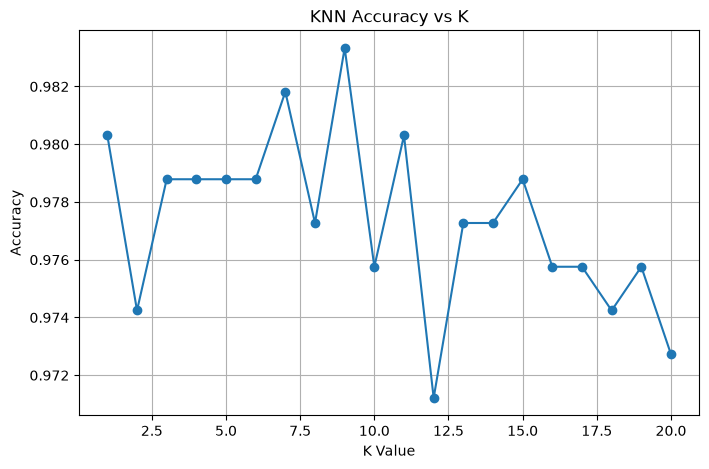

In [28]:
#Visualising the accuracy of model for different values of k
from sklearn.metrics import accuracy_score
k_values = range(1, 21)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(train_x, train_y)
    k_pred = model.predict(test_x)

    accuracies.append(accuracy_score(test_y, k_pred))

plt.figure(figsize=(8,5))
plt.plot(k_values, accuracies, marker='o')
plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs K")
plt.grid(True)
plt.show()

In [29]:
# Classification Report
from sklearn.metrics import classification_report
print(classification_report(test_y,  y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        30
           2       0.94      1.00      0.97        30
           3       1.00      1.00      1.00        30
           4       1.00      1.00      1.00        30
           5       1.00      1.00      1.00        30
           6       0.94      1.00      0.97        30
           7       1.00      1.00      1.00        30
           8       0.80      0.93      0.86        30
           9       0.97      1.00      0.98        30
          10       1.00      1.00      1.00        30
          11       1.00      0.93      0.97        30
          12       1.00      1.00      1.00        30
          13       1.00      0.97      0.98        30
          14       1.00      1.00      1.00        30
          15       1.00      1.00      1.00        30
          16       1.00      1.00      1.00        30
          17       1.00    

* KNN (k=5, unscaled) reached 98.70% training and 97.88% test accuracy. 
* The accuracy-vs-k plot stays between roughly 97.1% and 98.3% for k=1–20, so the result is not sensitive to k
* k=5 was kept rather than the peak at k=9, to avoid choosing k on the test set. The weakest classes are rice (recall 0.77) and jute (precision 0.80): about 7 of 30 rice samples were misclassified, most likely as jute.
* Since KNN is distance-based, features with large ranges (K, rainfall) dominate the distance, so a scaled version is evaluated in the model comparison.

#### Decision Tree

In [30]:
#Using Decision Tree Classifier for model building by "gini"

from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(random_state=42,max_depth=10,criterion="gini")
clf.fit(train_x, train_y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at

In [31]:
# Predict crop for train data
y_train_pred = clf.predict(train_x)

# Predict crop for test data
y_pred = clf.predict(test_x)
y_pred

array([ 9, 13,  2,  8,  8,  9, 17, 12,  5, 11, 20, 17,  4, 16, 12,  1, 10,
        3,  2,  6, 12, 15,  1,  9, 18, 17,  8, 12,  9,  7, 13,  8, 14, 19,
       13, 20,  9,  6,  2,  7, 13,  0,  4, 21,  6,  9, 11,  3, 16,  6, 12,
        9, 15, 10,  0,  1,  0, 11,  1,  4, 10,  3,  1, 18,  4, 20, 18, 17,
        5, 20, 16, 21,  5,  1,  3,  8, 15, 18, 11,  2,  7,  6,  7, 16,  3,
        2, 18,  8,  5,  4, 10, 21,  7,  7,  1,  7,  0, 19, 14, 17,  8,  1,
        5, 15, 18,  3,  7, 21, 19, 17, 16, 13, 19,  7,  8, 21, 12, 20,  6,
       13, 14, 18, 16,  7, 15, 12,  4,  6, 13,  3, 19, 19, 16,  9,  9,  8,
       14, 21, 18,  0, 11, 12, 16,  5, 17,  5,  8,  7, 12, 16,  8,  9, 15,
       19,  9, 10, 10, 17, 19,  9, 11, 10,  2,  4, 16, 15,  5,  9, 10, 21,
        8,  3,  7, 13,  0, 21, 21, 18, 14,  8,  5, 17, 11,  8,  8,  1,  2,
        3, 11,  4,  2, 18,  5, 17, 12, 21, 15, 15, 21, 15,  0,  2, 16, 13,
       21, 19,  4, 20, 15, 11,  9, 15, 14,  0, 11, 12,  9, 19, 13,  0,  7,
       21,  4,  6, 14, 10

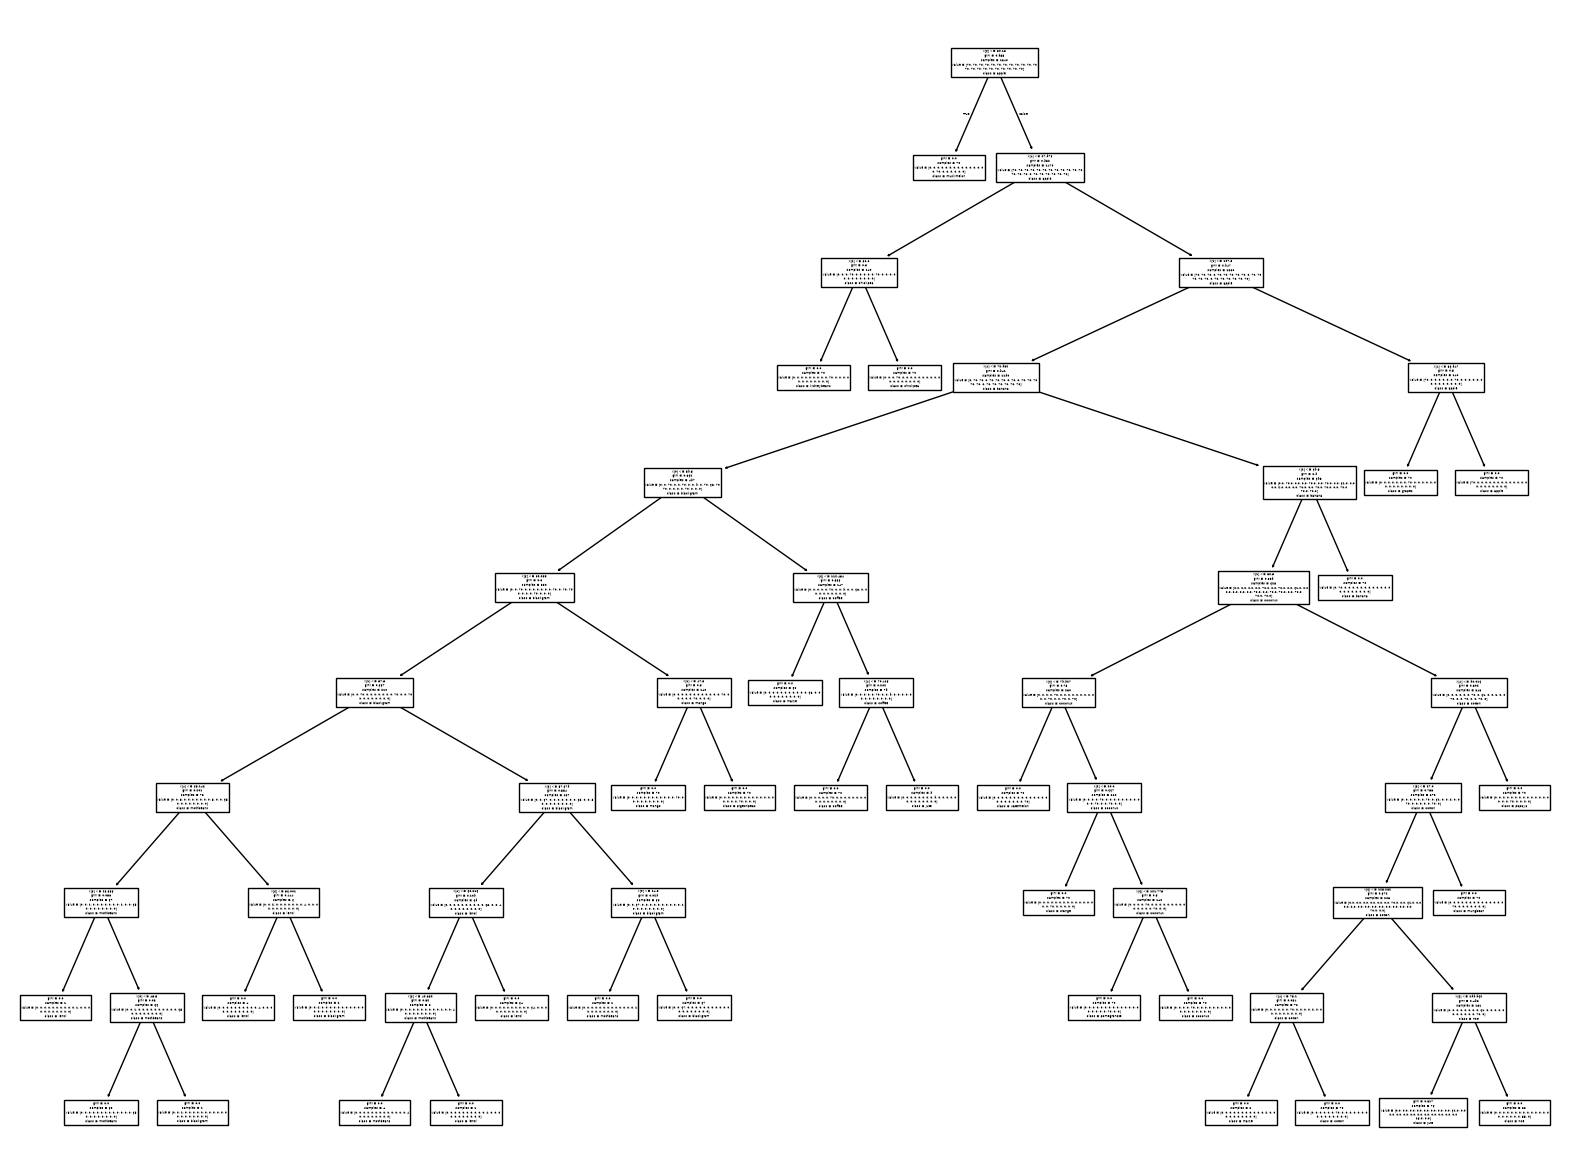

In [32]:
#Model Visualization
from sklearn import tree
plt.figure(figsize=(20,15))
tree.plot_tree(clf, 
               class_names= label_encoder.classes_,proportion = False)
plt.show()

In [33]:
#Model visualization
from sklearn.tree import export_text
r = export_text(clf, feature_names = train_x.columns)
print(r)

|--- rainfall <= 30.18
|   |--- class: 15
|--- rainfall >  30.18
|   |--- humidity <= 27.98
|   |   |--- K <= 50.00
|   |   |   |--- class: 9
|   |   |--- K >  50.00
|   |   |   |--- class: 3
|   |--- humidity >  27.98
|   |   |--- P <= 107.50
|   |   |   |--- humidity <= 72.93
|   |   |   |   |--- N <= 59.50
|   |   |   |   |   |--- rainfall <= 82.25
|   |   |   |   |   |   |--- P <= 57.50
|   |   |   |   |   |   |   |--- humidity <= 65.15
|   |   |   |   |   |   |   |   |--- temperature <= 23.54
|   |   |   |   |   |   |   |   |   |--- class: 10
|   |   |   |   |   |   |   |   |--- temperature >  23.54
|   |   |   |   |   |   |   |   |   |--- N <= 45.50
|   |   |   |   |   |   |   |   |   |   |--- class: 13
|   |   |   |   |   |   |   |   |   |--- N >  45.50
|   |   |   |   |   |   |   |   |   |   |--- class: 2
|   |   |   |   |   |   |   |--- humidity >  65.15
|   |   |   |   |   |   |   |   |--- rainfall <= 56.00
|   |   |   |   |   |   |   |   |   |--- class: 10
|   |   |   |   | 

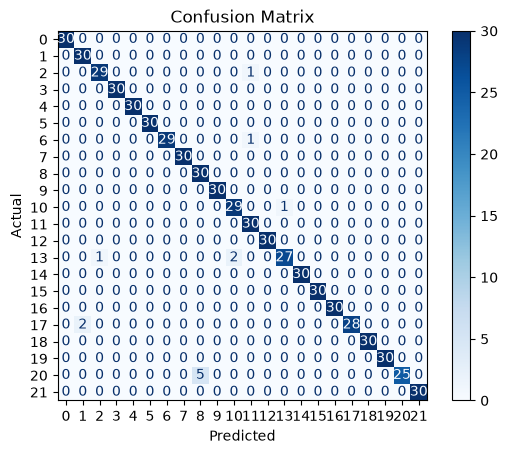

In [34]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

conf_matrix = confusion_matrix(test_y, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix)
disp.plot(cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [35]:
#validation of built model
from sklearn.metrics import accuracy_score

print('The accuracy of the Decision Tree for training data is {}%'.format(round(accuracy_score(y_train_pred,train_y)*100,2)))
print('The accuracy of the Decision Tree for test data is {}%'.format(round(accuracy_score(y_pred,test_y)*100,2)))

The accuracy of the Decision Tree for training data is 99.03%
The accuracy of the Decision Tree for test data is 98.03%


In [36]:
#Using Decision Tree Classifier for model building by "entropy"

from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(random_state=42,max_depth=10,criterion="entropy")
clf.fit(train_x, train_y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples

In [37]:
# Predict crop for train data
y_train_pred = clf.predict(train_x)

# Predict Species for test data
pred = clf.predict(test_x)
pred

array([ 9, 13, 13,  8,  8,  9, 17, 12,  5, 11, 20, 17,  4, 16, 12,  1, 10,
        3,  2,  6, 12, 15,  1,  9, 18, 17,  8, 12,  9,  7, 13,  8, 14, 19,
       13, 20,  9,  6,  2,  7, 13,  0,  4, 21,  6,  9, 11,  3, 16,  6, 12,
        9, 15, 10,  0,  1,  0, 11,  1,  4, 10,  3,  1, 18,  4, 20, 18, 17,
        5, 20, 16, 21,  5,  1,  3,  8, 15, 18, 11,  2,  7,  6,  7, 16,  3,
        2, 18, 20,  5,  4, 10, 21,  7,  7,  1,  7,  0, 19, 14, 17,  8,  1,
        5, 15, 18,  3,  7, 21, 19, 17, 16, 13, 19,  7,  8, 21, 12, 20,  6,
       13, 14, 18, 16,  7, 15, 12,  4,  6, 13,  3, 19, 19, 16,  9,  9,  8,
       14, 21, 18,  0, 11, 12, 16,  5, 17,  5,  8,  7, 12, 16,  8,  9, 15,
       19,  9, 10, 10, 17, 19,  9, 11, 10,  2,  4, 16, 15,  5,  9, 10, 21,
        8,  3,  7, 13,  0, 21, 21, 18, 14,  8,  5, 17, 11,  8,  8,  1, 13,
        3, 11,  4,  2, 18,  5, 17, 12, 21, 15, 15, 21, 15,  0,  2, 16, 13,
       21, 19,  4, 20, 15, 11,  9, 15, 14,  0, 11, 12,  9, 19, 13,  0,  7,
       21,  4,  6, 14, 10

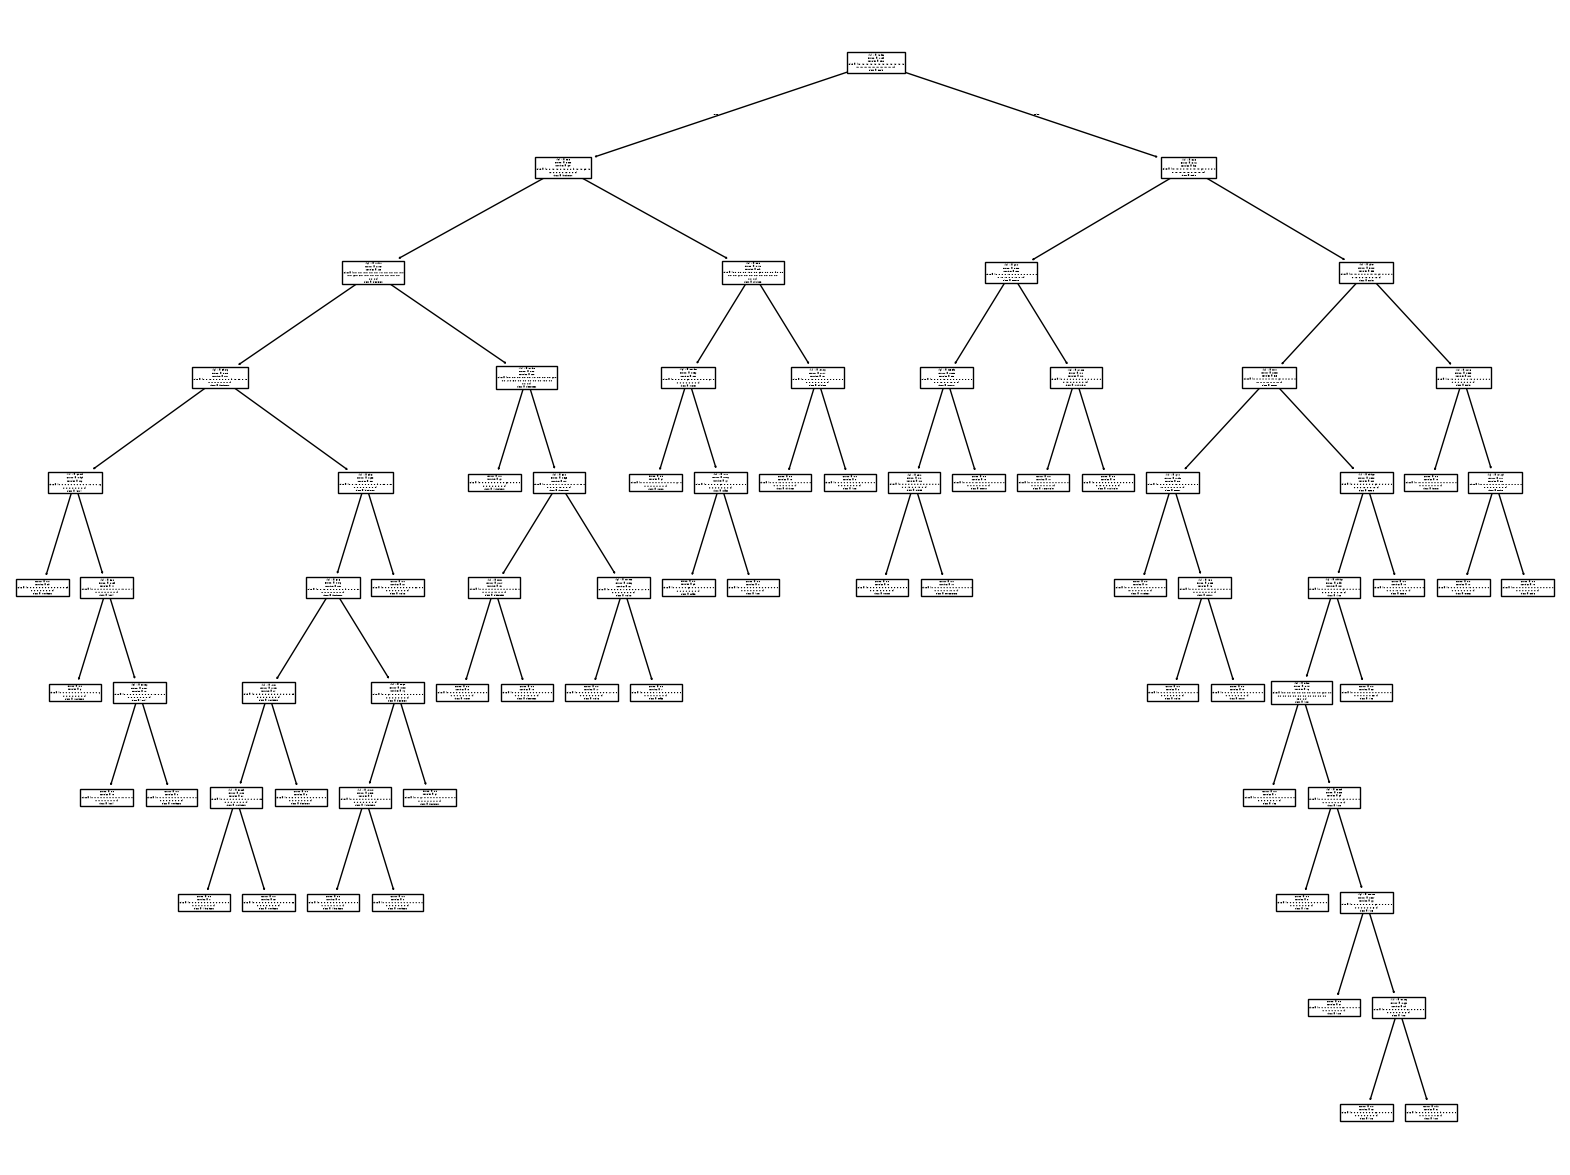

In [38]:
#Model Visualization
from sklearn import tree
plt.figure(figsize=(20,15))
tree.plot_tree(clf, 
               class_names= label_encoder.classes_,proportion = False)
plt.show()

In [39]:
#Model visualization
from sklearn.tree import export_text
r = export_text(clf, feature_names = train_x.columns)
print(r)

|--- humidity <= 72.93
|   |--- K <= 25.50
|   |   |--- rainfall <= 74.97
|   |   |   |--- rainfall <= 59.28
|   |   |   |   |--- humidity <= 60.03
|   |   |   |   |   |--- class: 13
|   |   |   |   |--- humidity >  60.03
|   |   |   |   |   |--- P <= 52.00
|   |   |   |   |   |   |--- class: 13
|   |   |   |   |   |--- P >  52.00
|   |   |   |   |   |   |--- temperature <= 30.14
|   |   |   |   |   |   |   |--- class: 10
|   |   |   |   |   |   |--- temperature >  30.14
|   |   |   |   |   |   |   |--- class: 13
|   |   |   |--- rainfall >  59.28
|   |   |   |   |--- N <= 59.50
|   |   |   |   |   |--- P <= 57.50
|   |   |   |   |   |   |--- N <= 40.50
|   |   |   |   |   |   |   |--- humidity <= 31.29
|   |   |   |   |   |   |   |   |--- class: 9
|   |   |   |   |   |   |   |--- humidity >  31.29
|   |   |   |   |   |   |   |   |--- class: 13
|   |   |   |   |   |   |--- N >  40.50
|   |   |   |   |   |   |   |--- class: 2
|   |   |   |   |   |--- P >  57.50
|   |   |   |   |   |   |

In [40]:
#validation of built model
from sklearn.metrics import accuracy_score
print('The accuracy of the Decision Tree for training data is {}%'.format(round(accuracy_score(y_train_pred,train_y)*100,2)))
print('The accuracy of the Decision Tree for test data is {}%'.format(round(accuracy_score(pred,test_y)*100,2)))

The accuracy of the Decision Tree for training data is 99.68%
The accuracy of the Decision Tree for test data is 98.79%


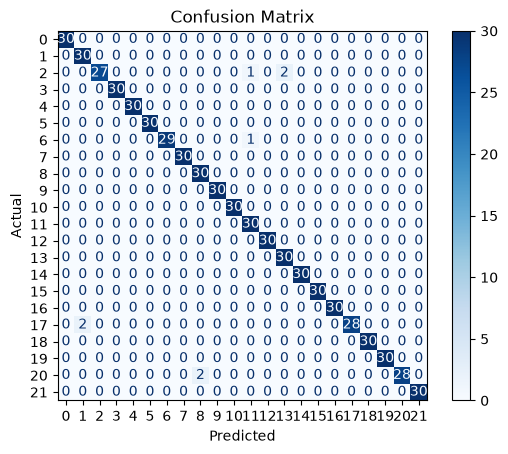

In [41]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

conf_matrix = confusion_matrix(test_y, pred)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix)
disp.plot(cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [42]:
# Classification Report
from sklearn.metrics import classification_report
print(classification_report(test_y, pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       0.94      1.00      0.97        30
           2       1.00      0.90      0.95        30
           3       1.00      1.00      1.00        30
           4       1.00      1.00      1.00        30
           5       1.00      1.00      1.00        30
           6       1.00      0.97      0.98        30
           7       1.00      1.00      1.00        30
           8       0.94      1.00      0.97        30
           9       1.00      1.00      1.00        30
          10       1.00      1.00      1.00        30
          11       0.94      1.00      0.97        30
          12       1.00      1.00      1.00        30
          13       0.94      1.00      0.97        30
          14       1.00      1.00      1.00        30
          15       1.00      1.00      1.00        30
          16       1.00      1.00      1.00        30
          17       1.00    

* Depth-10 trees reached 98.03% (gini) and 98.79% (entropy) test accuracy, with training accuracy of 99.03% and 99.68%.
* Entropy was ahead by about 5 test samples, which is too small to call a real difference from a single split.
* The ~1 point train–test gap shows mild overfitting. Humidity, K and rainfall appear near the top of both trees. The weakest classes for the entropy tree are blackgram (recall 0.90) and rice (recall 0.93).

#### Random Forest

In [43]:
from sklearn.ensemble import RandomForestClassifier
rfcl = RandomForestClassifier(criterion = 'entropy', max_depth = 10, min_samples_leaf=5, random_state=42)
rfcl = rfcl.fit(train_x, train_y)
train_pred = rfcl.predict(train_x)
test_pred = rfcl.predict(test_x)

In [44]:
print('The accuracy of the Random forest for training data is:', accuracy_score(train_pred,train_y))
print("The accuracy of Random forest model for test data: ", accuracy_score(test_pred,test_y))

The accuracy of the Random forest for training data is: 0.9980519480519481
The accuracy of Random forest model for test data:  0.9954545454545455


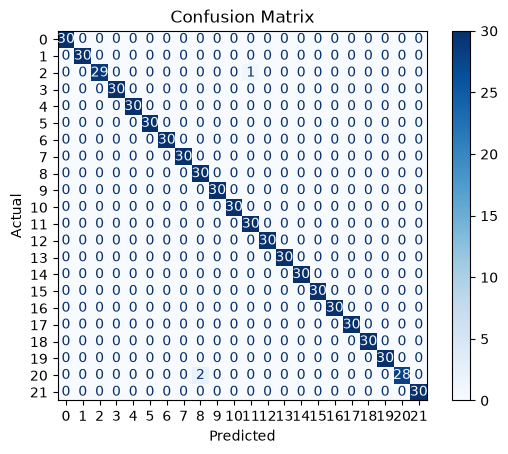

In [45]:
conf_matrix = confusion_matrix(test_y, test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix)
disp.plot(cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [46]:
print(classification_report(test_y, test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        30
           2       1.00      0.97      0.98        30
           3       1.00      1.00      1.00        30
           4       1.00      1.00      1.00        30
           5       1.00      1.00      1.00        30
           6       1.00      1.00      1.00        30
           7       1.00      1.00      1.00        30
           8       0.94      1.00      0.97        30
           9       1.00      1.00      1.00        30
          10       1.00      1.00      1.00        30
          11       0.97      1.00      0.98        30
          12       1.00      1.00      1.00        30
          13       1.00      1.00      1.00        30
          14       1.00      1.00      1.00        30
          15       1.00      1.00      1.00        30
          16       1.00      1.00      1.00        30
          17       1.00    

* The Random Forest reached 99.81% training and 99.55% test accuracy, making only 3 errors out of 660 test samples: two rice samples predicted as jute and one blackgram predicted as maize. 

### Model Comparison

In [47]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score


models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=10,criterion="entropy",random_state=42),
    "Random Forest": RandomForestClassifier(max_depth=10,criterion="entropy",min_samples_leaf=5,random_state=42),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "SVM": make_pipeline(StandardScaler(), SVC(probability=True, random_state=42)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, m in models.items():
    m.fit(train_x, train_y)
    pred_m = m.predict(test_x)
    
    scores = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
    
    rows.append([name, accuracy_score(test_y, pred_m), f1_score(test_y, pred_m, average="macro"), scores.mean(), scores.std()])

results = pd.DataFrame(rows, columns=["Model", "Accuracy", "Macro F1", "CV Mean Accuracy", "CV Std"]).sort_values("Accuracy", ascending=False)
results

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use 

,Model,Accuracy,Macro F1,CV Mean Accuracy,CV Std
1,Random Forest,0.995455,0.995451,0.994545,0.002318
3,SVM,0.989394,0.989366,0.983636,0.004407
0,Decision Tree,0.987879,0.987837,0.982273,0.005821
2,KNN,0.978788,0.978619,0.971364,0.006833


* All models were evaluated on the same stratified split and the same 5 folds.
* KNN and SVM were scaled but tree-based models were not as they do not need it.
* Here, SVM and KNN used default hyperparameters.
* Random Forest was best on both the test split and in cross-validation, and the most stable across folds (std 0.23%).
* Tree-based models outperformed KNN and SVM and is consistent with the threshold-like feature ranges seen in the EDA for overllapping classes.
* SVM and the Decision Tree are statistically comparable, and KNN was the weakest. Tuning SVM and KNN might narrow the gap.

* Checking for any giveaway doesn't gave any high value for any of the features like 0.5 or 0.8.
* So, there is no giveaway in the test dataset for the models.

In [49]:
print("Duplicate rows:", df.duplicated().sum())

# Check top 10 most important features for suspicious "giveaway" columns
importances = pd.Series(rfcl.feature_importances_, index=X.columns)
print(importances.sort_values(ascending=False).head(10))


Duplicate rows: 0
humidity       0.231168
K              0.199059
rainfall       0.191236
N              0.149774
P              0.142217
temperature    0.059937
ph             0.026608
dtype: float64


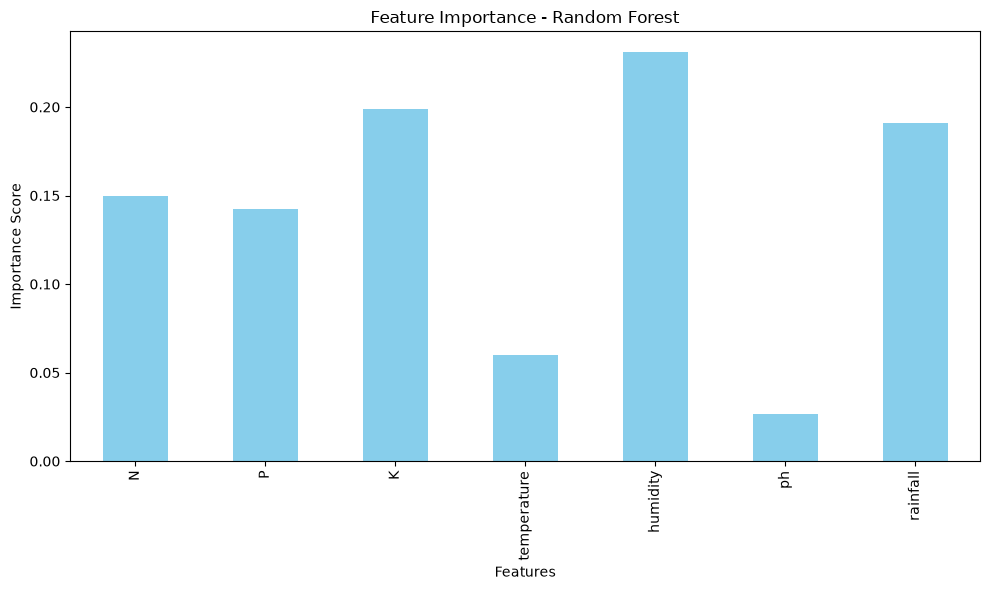

In [50]:
plt.figure(figsize=(10, 6))
importances.plot(kind='bar', color='skyblue')

plt.title('Feature Importance - Random Forest')
plt.xlabel('Features')
plt.ylabel('Importance Score')

plt.tight_layout()
plt.show()



Feature importance shows humidity (0.23), K (0.20) and rainfall (0.19) account for about 62% of the total, followed by N (0.15) and P (0.14); temperature (0.06) and pH (0.03) matter least.

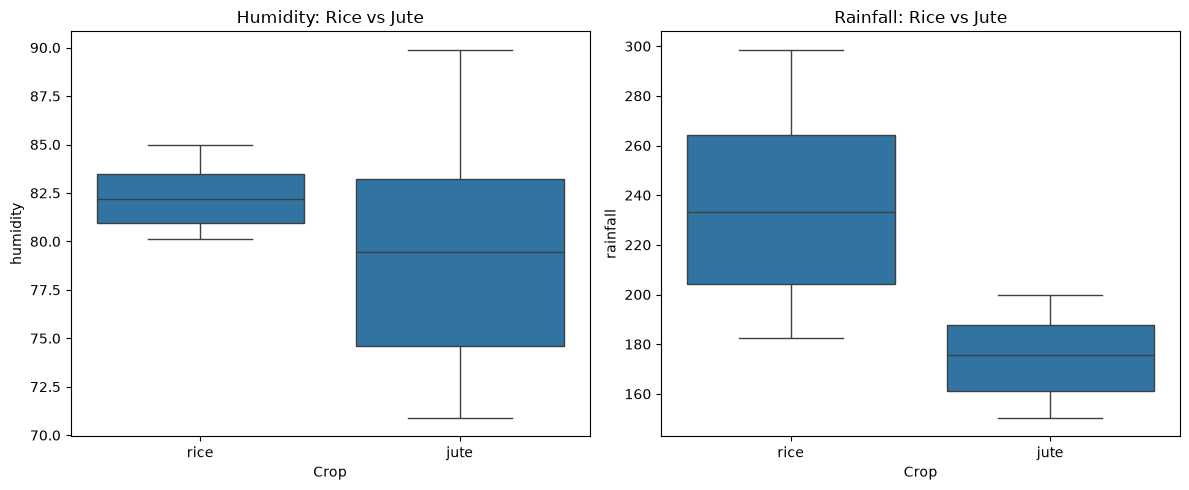

crop             jute   rice
humidity count  100.0  100.0
         mean    79.6   82.3
         std      5.5    1.4
         min     70.9   80.1
         25%     74.6   81.0
         50%     79.5   82.2
         75%     83.2   83.5
         max     89.9   85.0
rainfall count  100.0  100.0
         mean   174.8  236.2
         std     15.1   34.3
         min    150.2  182.6
         25%    161.1  204.3
         50%    175.6  233.1
         75%    187.6  264.1
         max    199.8  298.6


In [57]:
# Rice vs Jute: compare the features the model confuses them on
plot_df = df.copy()
plot_df['crop'] = label_encoder.inverse_transform(plot_df['label'])  # numbers -> crop names

subset = plot_df[plot_df['crop'].isin(['rice', 'jute'])]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, ['humidity', 'rainfall']):
    sns.boxplot(data=subset, x='crop', y=col, order=['rice', 'jute'], ax=ax)
    ax.set_title(f'{col.capitalize()}: Rice vs Jute')
    ax.set_xlabel('Crop')
plt.tight_layout()
plt.show()

# Numbers to base your written observation on
print(subset.groupby('crop')[['humidity', 'rainfall']].describe().T.round(1))

**Observation: Rice vs Jute**

- **Rainfall is the main separating feature.** Rice needs much more rainfall (mean ≈ 236 mm, range 183–299 mm) than jute (mean ≈ 175 mm, range 150–200 mm). The two ranges overlap only in a narrow band of about 183–200 mm.
- **Humidity separates them poorly.** Rice has a narrow humidity range (80–85%, std 1.4), while jute is much more variable (71–90%, std 5.5). Rice's range sits entirely inside jute's, so humidity alone cannot tell them apart.
- **Why they get confused:** a rice sample with relatively low rainfall (close to 200 mm) and humidity of 80–85% looks like a typical jute sample. This explains why the models misclassify rice as jute, as seen in the confusion matrices. The reverse (jute predicted as rice) is rarer because jute rarely has rainfall above 200 mm.

### Conclusion

* The saved model was trained on the 70% split.
* A Random Forest (with max_depth=10, entropy, min_samples_leaf=5) recommends one of 22 crops from soil nutrients (N, P, K), pH, temperature, humidity and rainfall with ~99.5% accuracy (99.45% ± 0.23% in 5-fold CV).
* Humidity, potassium and rainfall are the most influential features.
* The main remaining confusion is between rice and jute, which probably have similar humidity and rainfall profiles.
* Limitations: the dataset is clean, balanced and highly separable, so real-world accuracy would likely be lower; the model was not validated on real farm data; SVM and KNN were not tuned. The model is saved and ready to be deployed as a Streamlit app.

In [53]:
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

def recommend_crop(N, P, K, temperature, humidity, ph, rainfall,
                   model, label_encoder=None, top_n=3):
    """Return the top_n recommended crops with their probabilities."""
    # Keep the same column names and order used in training
    sample = pd.DataFrame([[N, P, K, temperature, humidity, ph, rainfall]],
                          columns=FEATURES)

    probs = model.predict_proba(sample)[0]
    top_idx = np.argsort(probs)[::-1][:top_n]

    # Map class indices back to crop names
    if label_encoder is not None:
        class_labels = label_encoder.inverse_transform(model.classes_)
    else:
        class_labels = model.classes_      # already crop names

    return pd.DataFrame({
        "Crop": class_labels[top_idx],
        "Confidence (%)": (probs[top_idx] * 100).round(1)
    })

In [55]:
# Use your best model and your fitted LabelEncoder
recommend_crop(N=12, P=39, K=21, temperature=28.99319, humidity=62.859482, ph=8.183845, rainfall=70.471304,
               model=rfcl, label_encoder=label_encoder)
						

,Crop,Confidence (%)
0,mothbeans,81.0
1,blackgram,13.5
2,lentil,3.0


In [56]:
def check_ranges(values: dict, df):
    warnings = []
    for col, val in values.items():
        lo, hi = df[col].min(), df[col].max()
        if not (lo <= val <= hi):
            warnings.append(f"{col}={val} is outside the training range ({lo:.1f} to {hi:.1f}); the prediction may be unreliable.")
    return warnings

crop_val = {}
for col in df.columns:
    if col != "label":
        in_val = float(input(f"Enter the value for {col}: "))
        crop_val[col]= in_val

print(check_ranges(crop_val,df))
    

Enter the value for N:  56
Enter the value for P:  78
Enter the value for K:  90
Enter the value for temperature:  49
Enter the value for humidity:  200
Enter the value for ph:  8
Enter the value for rainfall:  789


['temperature=49.0 is outside the training range (8.8 to 43.7); the prediction may be unreliable.', 'humidity=200.0 is outside the training range (14.3 to 100.0); the prediction may be unreliable.', 'rainfall=789.0 is outside the training range (20.2 to 298.6); the prediction may be unreliable.']


In [ ]:
import joblib
joblib.dump(rfcl, "crop_model.joblib")
joblib.dump(label_encoder, "label_encoder.joblib")